### Imports

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import time
import warnings
warnings.filterwarnings("ignore")

# Can change to cpu
device = "cuda:0"

### Cube function that the model uses

In [2]:
class Cube(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)

    def forward(self, x):
        return x**3 / 6

In [3]:
class DieSetEncoder(nn.Module):
    """
    Permutation-invariant ("deep sets") encoder over the dies in a scenario.
    Each die (xmin, ymin, xmax, ymax) is embedded independently by a shared
    MLP, then SUMMED across dies. Sum (rather than mean) pooling lets the
    downstream network pick up on how many dies are present -- not just
    their "average" footprint -- while staying exactly invariant to die
    order and to the number of padding slots (which are masked to zero).

    Because this only depends on the die layout (not on the query point),
    it should be computed ONCE per scenario and reused for every query
    point in that scenario -- see how it's used in train() / evaluate_warpage_arbitrary_domain.
    """
    def __init__(self, embed_dim=64, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, hidden),
            nn.GELU(),
            nn.Linear(hidden, embed_dim),
        )

    def forward(self, die_bboxes, mask=None):
        # die_bboxes: (..., n_dies, 4)
        e = self.net(die_bboxes)           # (..., n_dies, embed_dim)
        if mask is not None:
            e = e * mask.unsqueeze(-1)
        return e.sum(dim=-2)               # (..., embed_dim)


class WarpageNet(nn.Module):
    """
    w(x, y) predictor, conditioned on:
      - query point (x, y)
      - permutation-invariant die-scene embedding (DieSetEncoder output)
      - domain shape, as a single scalar log(Lx / Ly)

    Domain AREA is intentionally not an input: every scenario this model is
    trained (and queried, via evaluate_warpage_arbitrary_domain) on has unit
    area by construction, so area carries no information and Ly is fully
    determined by Lx (Ly = 1/Lx) -- passing both Lx and Ly would just be a
    redundant, perfectly-correlated pair of features.
    """
    def __init__(self, embed_dim=64, trunk_hidden=256):
        super().__init__()
        self.die_encoder = DieSetEncoder(embed_dim=embed_dim)
        in_dim = 2 + embed_dim + 1  # (x, y) + pooled die embedding + log-aspect-ratio
        self.trunk = nn.Sequential(
            nn.Linear(in_dim, trunk_hidden),
            nn.GELU(),
            nn.Linear(trunk_hidden, trunk_hidden),
            nn.GELU(),
            nn.Linear(trunk_hidden, trunk_hidden),
            nn.GELU(),
            nn.Linear(trunk_hidden, 128),
            Cube(),
            nn.Linear(128, 128),
            nn.GELU(),
            nn.Linear(128, 64),
            nn.GELU(),
            nn.Linear(64, 32),
            nn.GELU(),
            nn.Linear(32, 1),
        )

    def forward(self, xy, die_bboxes=None, mask=None, domain_feat=None, pooled_die_embed=None):
        """
        xy: (B, 2)
        domain_feat: (B, 1) -- log(Lx/Ly) for each point's scenario
        Either pass die_bboxes (+ optional mask) to embed on the fly, or
        pass an already-pooled pooled_die_embed (B, embed_dim) computed once
        per scenario and broadcast -- much cheaper during training, since
        many query points share the same scenario.
        """
        if pooled_die_embed is None:
            assert die_bboxes is not None, "must supply either die_bboxes or pooled_die_embed"
            pooled_die_embed = self.die_encoder(die_bboxes, mask)
        X = torch.cat([xy, pooled_die_embed, domain_feat], dim=-1)
        return self.trunk(X).squeeze(-1)

model = WarpageNet().to(device)

### Model definition and parameter loading

In [4]:
# Change path to model ckpt
model.load_state_dict(torch.load("variable_die_domain_model.pt", map_location=device))

<All keys matched successfully>

Warpage has rigidbody transformation degree of freedom.  This function subtracts out the rigidbody deformation so the mean w, mean w_x, and mean w_y are 0 to make comparisons / cost calculations consistent

In [5]:
def subtract_plane_of_best_fit(w, x, y):
    """
    Subtracts the plane of best fit from w
    """
    A = torch.stack([x.ravel(), y.ravel(), torch.ones_like(x.ravel())], dim=1)  # (N, 3)
    coeff = torch.linalg.lstsq(A, w.ravel().unsqueeze(-1)).solution  # (3, 1)
    a, b, c = coeff[0], coeff[1], coeff[2]
    plane = a * x + b * y + c
    return w - plane

### Function that takes bounding boxes and predicts the warpage

In [6]:
# Predicts warpage for a given set of die bboxes - assumes center of package is 0, 0
def predict_warpage(bboxes, substrate_width, substrate_height, grid_width=128, grid_height=128):

    assert max(substrate_width, substrate_height) / min(substrate_width, substrate_height) <= 4, "Aspect ratio too extreme"

    # Normalize to the unit-area domain the model was trained on, preserving aspect ratio
    scale = (substrate_width * substrate_height) ** 0.5  # physical length scale
    Lx = substrate_width / scale
    Ly = substrate_height / scale  # Lx * Ly == 1

    x_ = torch.linspace(-Lx / 2, Lx / 2, grid_width)
    y_ = torch.linspace(-Ly / 2, Ly / 2, grid_height)
    x, y = torch.meshgrid(x_, y_, indexing='ij')
    x, y = x.flatten().to(device), y.flatten().to(device)
    points = torch.stack([x, y], dim=-1)

    n_points = grid_width * grid_height

    bboxes = torch.cat([bboxes, torch.zeros(20 - bboxes.shape[0], 4)], dim=0) / scale
    bboxes = bboxes.to(device)
    area = (bboxes[:, 2] - bboxes[:, 0]) * (bboxes[:, 3] - bboxes[:, 1])
    mask = area > 1e-9

    with torch.no_grad():
        pooled = model.die_encoder(bboxes.unsqueeze(0), mask.unsqueeze(0))  # (1, embed_dim)
    pooled_rep = pooled.repeat_interleave(n_points, dim=0)

    log_aspect = torch.log(Lx / Ly) if isinstance(Lx, torch.Tensor) else torch.log(torch.tensor(Lx / Ly))
    domain_feat_rep = log_aspect.to(device).view(1, 1).repeat(n_points, 1)

    w_pred = model(points, pooled_die_embed=pooled_rep, domain_feat=domain_feat_rep).squeeze(-1)
    w_pred = subtract_plane_of_best_fit(w_pred, x, y)

    return w_pred.reshape(grid_width, grid_height) * scale ** 2

torch.Size([128, 128])


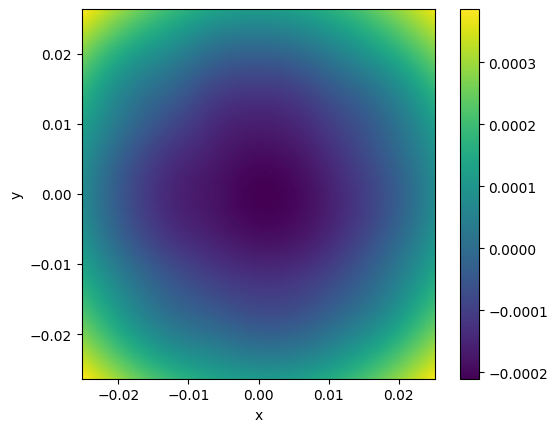

In [7]:
# VALUES PULLED FROM sample1_gen208_ind61

substrate_width = 50.451739 / 1000
substrate_height = 52.717695 / 1000

bboxes_mm = torch.tensor([
    [38.951739, 20.751582, 48.951739, 28.751582],
    [1.786474,  38.439161, 9.786474,  48.439161],
    [37.441341, 4.519235,  47.441341, 12.519235],
    [38.891959, 35.384479, 48.891959, 43.384479],
    [19.793611, 18.345835, 34.793611, 30.345835],
    [2.092416,  17.619084, 14.092416, 32.619084],
    [26.180295, 37.149947, 34.180295, 49.149947],
    [15.979806, 36.292506, 23.979806, 48.292506],
    [22.427579, 3.019805,  34.427579, 11.019805],
    [4.195329,  2.805663,  16.195329, 10.805663]
], dtype=torch.float32)

# Convert mm -> meters
bboxes_m = bboxes_mm / 1000.0

# Shift origin to center (subtract W/2 and H/2)
center_offset = torch.tensor([substrate_width / 2, substrate_height / 2, substrate_width / 2, substrate_height / 2])
bboxes = bboxes_m - center_offset

with torch.no_grad():
    w_pred = predict_warpage(bboxes, substrate_width, substrate_height)

print(w_pred.shape)

plt.imshow(
    w_pred.cpu().T,
    origin='lower',
    extent=[-substrate_width / 2, substrate_width / 2, -substrate_height / 2, substrate_height / 2],
)
plt.xlabel("x")
plt.ylabel("y")
plt.colorbar()
plt.show()

In [8]:
# Compute the Warpage RMS value
rms = torch.sqrt(torch.mean(w_pred ** 2))
print("WARPAGE RMS (mm) -->", rms.item() * 1000)

WARPAGE RMS (mm) --> 0.12848162441514432


In [9]:
t0 = time.time()

for _ in range(100):
    with torch.no_grad():
        w_pred = predict_warpage(bboxes, substrate_width, substrate_height)

print(f"Time to predict: {(time.time() - t0)/100:.4f}")

Time to predict: 0.0108
